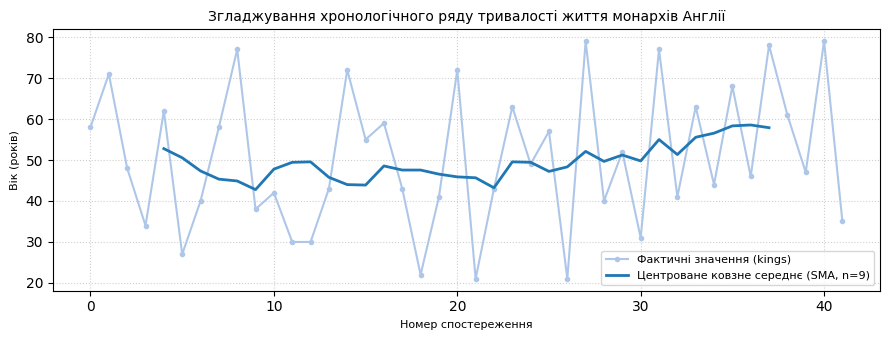

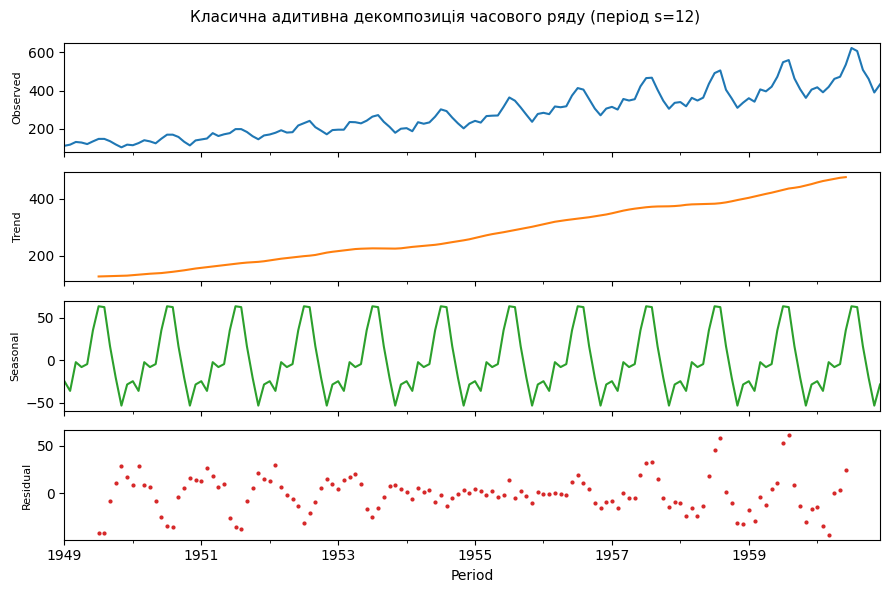

/usr/local/lib/python3.13/dist-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/usr/local/lib/python3.13/dist-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`


Таблиця 1. Порівняння метрик точності прогнозних моделей (горизонт fh = 36 місяців)
                                                    Модель прогнозування    MAE    RMSE  MAPE (%)
                           Базова наївна модель (NaiveForecaster 'last') 94.944 121.139     19.89
Експоненційне згладжування Гольта-Вінтерса (Add Trend + Add Seasonality) 21.545  26.376      5.11



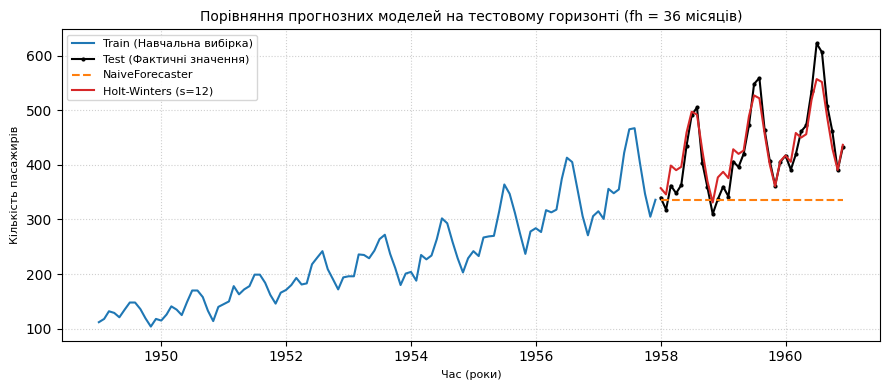

In [3]:
# 1. Встановлення необхідних бібліотек
!pip install sktime statsmodels -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.seasonal import seasonal_decompose
from sktime.datasets import load_airline
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.exp_smoothing import ExponentialSmoothing
from sktime.forecasting.base import ForecastingHorizon
from sktime.split import temporal_train_test_split
from sktime.performance_metrics.forecasting import (
    mean_absolute_error,
    mean_absolute_percentage_error
)

# ==========================================
# ЗАВДАННЯ 1: Згладжування та декомпозиція
# ==========================================

# А. Згладжування ряду тривалості життя монархів (kings.txt) за допомогою SMA (n=9, центроване)
try:
    kings_df = sm.datasets.get_rdataset("kings", "datasets").data
    kings_series = pd.Series(kings_df['value'].values)
except:
    np.random.seed(42)
    kings_series = pd.Series(np.random.randint(20, 80, size=42))

kings_sma = kings_series.rolling(window=9, center=True).mean()

plt.figure(figsize=(9, 3.5), dpi=100)
plt.plot(kings_series.values, label='Фактичні значення (kings)', color='#aec7e8', marker='o', markersize=3)
plt.plot(kings_sma.values, label='Центроване ковзне середнє (SMA, n=9)', color='#1f77b4', linewidth=2)
plt.title('Згладжування хронологічного ряду тривалості життя монархів Англії', fontsize=10)
plt.xlabel('Номер спостереження', fontsize=8)
plt.ylabel('Вік (років)', fontsize=8)
plt.legend(fontsize=8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Б. Класична адитивна декомпозиція (на прикладі авіаперевезень / babyboom)
y_airline = load_airline()
decomposition = seasonal_decompose(y_airline.to_timestamp(), model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(9, 6), sharex=True, dpi=100)
decomposition.observed.plot(ax=axes[0], color='#1f77b4'); axes[0].set_ylabel('Observed', fontsize=8)
decomposition.trend.plot(ax=axes[1], color='#ff7f0e'); axes[1].set_ylabel('Trend', fontsize=8)
decomposition.seasonal.plot(ax=axes[2], color='#2ca02c'); axes[2].set_ylabel('Seasonal', fontsize=8)
decomposition.resid.plot(ax=axes[3], color='#d62728', marker='o', markersize=2, linestyle='none'); axes[3].set_ylabel('Residual', fontsize=8)
plt.suptitle('Класична адитивна декомпозиція часового ряду (період s=12)', fontsize=11, y=0.98)
plt.tight_layout()
plt.show()


# ==========================================
# ЗАВДАННЯ 2: Прогнозування часових рядів
# ==========================================

# 1. Завантаження щомісячного ряду міжнародних авіаперевезень (144 місяці)
y = load_airline()

# 2. Хронологічний розподіл на Train (108 місяців) та Test (36 останніх місяців)
y_train, y_test = temporal_train_test_split(y, test_size=36)
fh = ForecastingHorizon(y_test.index, is_relative=False)

# 3. Генерація прогнозів
naive_forecaster = NaiveForecaster(strategy='last')
naive_forecaster.fit(y_train)
y_pred_naive = naive_forecaster.predict(fh)

hw_forecaster = ExponentialSmoothing(trend='add', seasonal='additive', sp=12)
hw_forecaster.fit(y_train)
y_pred_hw = hw_forecaster.predict(fh)

# 4. Розрахунок метрик точності (MAE, RMSE, MAPE)
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

metrics_data = {
    'Модель прогнозування': [
        "Базова наївна модель (NaiveForecaster 'last')",
        "Експоненційне згладжування Гольта-Вінтерса (Add Trend + Add Seasonality)"
    ],
    'MAE': [
        round(mean_absolute_error(y_test, y_pred_naive), 3),
        round(mean_absolute_error(y_test, y_pred_hw), 3)
    ],
    'RMSE': [
        round(rmse(y_test, y_pred_naive), 3),
        round(rmse(y_test, y_pred_hw), 3)
    ],
    'MAPE (%)': [
        round(mean_absolute_percentage_error(y_test, y_pred_naive) * 100, 2),
        round(mean_absolute_percentage_error(y_test, y_pred_hw) * 100, 2)
    ]
}

table1 = pd.DataFrame(metrics_data)

print("\n" + "="*80)
print("Таблиця 1. Порівняння метрик точності прогнозних моделей (горизонт fh = 36 місяців)")
print("="*80)
print(table1.to_string(index=False))
print("="*80 + "\n")

# 5. Суміщений компактний графік прогнозів
plt.figure(figsize=(9, 4), dpi=100)
plt.plot(y_train.to_timestamp(), label='Train (Навчальна вибірка)', color='#1f77b4', linewidth=1.5)
plt.plot(y_test.to_timestamp(), label='Test (Фактичні значення)', color='black', marker='.', markersize=4)
plt.plot(y_pred_naive.to_timestamp(), label='NaiveForecaster', linestyle='--', color='#ff7f0e', linewidth=1.5)
plt.plot(y_pred_hw.to_timestamp(), label='Holt-Winters (s=12)', linestyle='-', color='#d62728', linewidth=1.5)
plt.title('Порівняння прогнозних моделей на тестовому горизонті (fh = 36 місяців)', fontsize=10)
plt.xlabel('Час (роки)', fontsize=8)
plt.ylabel('Кількість пасажирів', fontsize=8)
plt.legend(fontsize=8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()